# Model 12: linear-mean GP, anisotropic Matérn kernels, trained noise term

**Purpose.** Fit one GC-GP model form to all seven properties and score it on a
single train/test split (80/20 unless the run plan sets `testSize`). This is one of the twelve models compared in the
kernel study (summarized in `03_Kernel_Comparison.ipynb`).

**Model form (method 4):** `y = GP(a·MW + b·y_GC + c, K(MW, y_GC))`

The GP learns the experimental value around a straight-line fit on both inputs. The line (a, b, c) is fitted together with the kernel hyperparameters.

**What this notebook produces** (in `Output_Data/kernel_comparison/<property>/model_4-opt8/`)

* `<property>_metrics.csv`: MAE, RMSE, R², MAPE and MPE on the training and test sets.
* `<property>_predictions.csv`: every prediction with its 95% interval.
* `<property>_GP_results.png` / `.pdf`: train, test and combined parity plots (600 dpi).
* `model_summary.txt`: fitted hyperparameters.

## 1. Environment and setup

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder that contains src/gcgp) and make the
# shared code importable. This works whether Jupyter starts in notebooks/ or
# in the repository root.
repoRoot = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gcgp").is_dir())
sys.path.insert(0, str(repoRoot / "src"))

import pandas as pd

from gcgp.settings import checkCuratedData, describeSetup, outputFolder, setGlobalSeed
from gcgp.singleSplit import compactSummary, runSingleSplitPlan
from gcgp.plotting import plotTestParityGrid
from gcgp.checkpoints import checkpointStatus

setGlobalSeed()
outputDir = outputFolder("kernel_comparison")
pd.set_option("display.precision", 3)
checkCuratedData()
print(describeSetup())
print(checkpointStatus())

Run mode      : FULL
Input folder  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Input_Data
Output folder : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data
Curated data  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/curated_data
GP workers    : 1 (set GCGP_N_WORKERS to fit restarts in parallel)
Global seed   : 42
Checkpoints   : resume from saved restarts; 1562 saved in /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/checkpoints


**Checkpoints.** Every GP optimizer restart is saved in
`Output_Data/checkpoints/` as soon as it finishes. If the notebook stops (or is
rerun), finished restarts are loaded instead of refitted, so the run resumes
where it stopped and gives the same numbers. Set the environment variable
`GCGP_RESUME=0` to ignore the saved restarts and refit everything.

**Parallel restarts.** Restarts that still have to be fitted can run in
parallel worker processes: set the environment variable `GCGP_N_WORKERS`
(for example 4) before starting the kernel, or use
`bash scripts/run_notebooks.sh --workers 4`. The results are bit-for-bit the
same for any number of workers; `scripts/benchmark_gp_workers.py` shows which
number is fastest on your computer.

## 2. Data and model settings

Each property is read from its curated dataset in `Output_Data/curated_data/`
(written by `00_Data_Curation.ipynb`). The inputs are molecular weight and the
GC estimate; the target is the CRC value.

Every entry of the run plan below lists the properties it applies to and the GP
settings used for them:

* `kernel`: covariance function (RQ, RBF, or a Matérn kernel).
* `anisotropic`: whether each input gets its own length scale.
* `optMethod`: SciPy optimizer for the hyperparameters.
* `trainLikelihood`: whether the noise term is fitted (if False it stays at 1e-5).
* `retrainGp`: number of random restarts; the best converged restart is kept.
* `testSize` (optional): fraction of molecules held out for testing; 0.2 when not given.

**Notes for this model.** Model 12 is Model 11 with a trained noise term (slide 19). It is the only model whose test set is 15% of the molecules instead of 20%, as in the original runs saved in `model_4-opt8`.

In [2]:
methodNumber = 4
saveName = "model_4-opt8"

runPlan = [
    {"properties": ["Tb", "Hvap", "Pc", "Vc", "logP"],
     "kernel": "Matern32", "anisotropic": True, "optMethod": "L-BFGS-B",
     "trainLikelihood": True, "retrainGp": 10, "testSize": 0.15},
    {"properties": ["Tm"],
     "kernel": "Matern12", "anisotropic": True, "optMethod": "BFGS",
     "trainLikelihood": True, "retrainGp": 10, "testSize": 0.15},
    {"properties": ["Tc"],
     "kernel": "Matern32", "anisotropic": True, "optMethod": "BFGS",
     "trainLikelihood": True, "retrainGp": 10, "testSize": 0.15},
]

pd.DataFrame(runPlan)

,properties,kernel,anisotropic,optMethod,trainLikelihood,retrainGp,testSize
0,"[Tb, Hvap, Pc, Vc, logP]",Matern32,True,L-BFGS-B,True,10,0.15
1,[Tm],Matern12,True,BFGS,True,10,0.15
2,[Tc],Matern32,True,BFGS,True,10,0.15


## 3. Fit and evaluate

For each property: split the molecules into training and test sets (seed 42), fit the GP with several
restarts, and predict both sets. The per-property figures are saved to disk
rather than shown here, to keep the notebook short; Section 4 shows an overview.

In [3]:
summary = runSingleSplitPlan(runPlan, methodNumber, saveName, outputDir, showPlot=False)
summary.to_csv(outputDir / f"{saveName}_summary.csv", index=False)

Tb: kernel=Matern32, anisotropic=True, optimizer=L-BFGS-B
Hvap: kernel=Matern32, anisotropic=True, optimizer=L-BFGS-B
Pc: kernel=Matern32, anisotropic=True, optimizer=L-BFGS-B
Vc: kernel=Matern32, anisotropic=True, optimizer=L-BFGS-B
logP: kernel=Matern32, anisotropic=True, optimizer=L-BFGS-B
Tm: kernel=Matern12, anisotropic=True, optimizer=BFGS
Tc: kernel=Matern32, anisotropic=True, optimizer=BFGS


## 4. Results

### 4.1 Metrics for every run

`Test_R2`, `Test_RMSE` and `Test_MAE` are measured on the 20% of molecules the
GP never saw. `CI_Test_Outside` is the fraction of test molecules whose
experimental value falls outside the predicted 95% interval; a well-calibrated
model should be close to 0.05.

In [4]:
compactSummary(summary)

,Property,Kernel,N_Train,N_Test,Train_R2,Test_R2,Test_RMSE,Test_MAE,CI_Test_Outside
0,Tb,Matern32,753,133,0.851,0.839,26.431,21.342,0.045
1,Hvap,Matern32,59,11,0.892,0.958,2.146,1.871,0.091
2,Pc,Matern32,64,11,0.879,0.688,5.165,3.234,0.091
3,Vc,Matern32,59,10,0.994,0.981,19.998,13.569,0.100
4,logP,Matern32,2531,447,0.988,0.932,0.412,0.294,0.027
5,Tm,Matern12,1563,276,0.665,0.575,57.095,44.814,0.080
6,Tc,Matern32,59,11,0.965,0.861,35.807,28.289,0.091


### 4.2 Test-set parity plots

Each panel shows the held-out molecules for one property. The error bars are the
95% prediction intervals and the dashed line is perfect agreement.

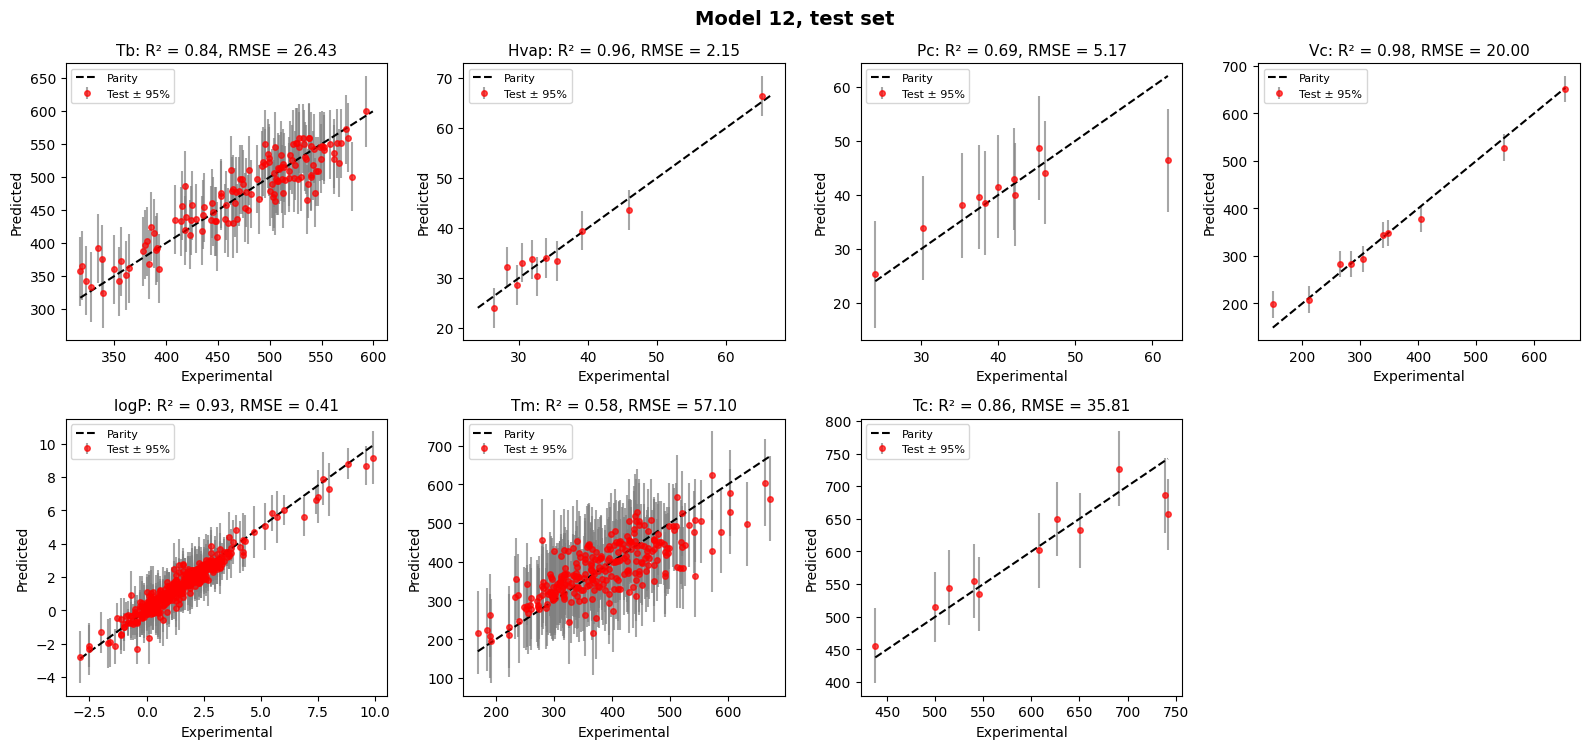

In [5]:
tables = {code: pd.read_csv(outputDir / code / saveName / f"{code}_predictions.csv")
          for code in summary["Property"]}
if tables:
    plotTestParityGrid(tables, f"Model {12}, test set",
                       savePath=outputDir / f"{saveName}_test_parity_overview.png")

## 5. Summary of the results

The text below is written from the metrics of this run and saved as
`results_summary.md` in this model's output folder. A run that could not be
fitted (for example when no optimizer restart converged) is reported and left
out instead of stopping the notebook. The metrics files are read by
`03_Kernel_Comparison.ipynb`, which puts all twelve models side by side.

In [6]:
from gcgp.narrative import describeSingleSplit, showAndSave

showAndSave(describeSingleSplit(summary, "Model 12: linear-mean GP, anisotropic Matérn kernels, trained noise term"),
            outputDir / f"{saveName}_results_summary.md");

## Model 12: linear-mean GP, anisotropic Matérn kernels, trained noise term: results

- Tb (753 train / 133 test): test R² = 0.839, RMSE = 26.43 K, MAE = 21.34 K; 95.5% of test molecules inside the 95% interval.
- ΔHvap (59 train / 11 test): test R² = 0.958, RMSE = 2.15 kJ/mol, MAE = 1.87 kJ/mol; 90.9% of test molecules inside the 95% interval.
- Pc (64 train / 11 test): test R² = 0.688, RMSE = 5.17 bar, MAE = 3.23 bar; 90.9% of test molecules inside the 95% interval.
- Vc (59 train / 10 test): test R² = 0.981, RMSE = 20.00 cm³/mol, MAE = 13.57 cm³/mol; 90.0% of test molecules inside the 95% interval.
- log P (2531 train / 447 test): test R² = 0.932, RMSE = 0.412, MAE = 0.294; 97.3% of test molecules inside the 95% interval.
- Tm (1563 train / 276 test): test R² = 0.575, RMSE = 57.10 K, MAE = 44.81 K; 92.0% of test molecules inside the 95% interval.
- Tc (59 train / 11 test): test R² = 0.861, RMSE = 35.81 K, MAE = 28.29 K; 90.9% of test molecules inside the 95% interval.
